<a href="https://colab.research.google.com/github/Anurima2206/Natural-Language-Processing/blob/main/spam_email_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df=pd.read_csv('emails.csv')

In [ ]:
df.head()

,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


In [ ]:
# Separate majority and minority classes
df_spam_0 = df[df['spam'] == 0]
df_spam_1 = df[df['spam'] == 1]

# Undersample majority class to match the minority class count
minority_count = len(df_spam_1)
df_spam_0_undersampled = df_spam_0.sample(n=minority_count, random_state=42)

# Combine back into a single balanced DataFrame
df_balanced = pd.concat([df_spam_0_undersampled, df_spam_1]).sample(frac=1, random_state=42).reset_index(drop=True)

# Check the new class distribution
print(df_balanced['spam'].value_counts())

spam
0    1368
1    1368
Name: count, dtype: int64


In [ ]:
df=df_balanced
df['spam'].value_counts()


,count
spam,
0,1368
1,1368


In [ ]:
# make lowercase
df['text']=df['text'].apply(lambda x:x.lower())

In [ ]:
#remove punctuations
import string
def remove_punc(text):
  return text.translate(str.maketrans('','',string.punctuation))
df['text']=df['text'].apply(remove_punc)

In [ ]:
#remove emojis
def remove_emojis(text):
  new=""
  for i in text:
    if i.isascii():
      new=new+i
  return new
df['text']=df['text'].apply(remove_emojis)

In [ ]:
#remove stopwords
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
stop_words=set(stopwords.words('english'))
def remove_stopwords(text):
  word_tokens=word_tokenize(text)
  cleaned=[i for i in word_tokens if i not in stop_words]
  return ' '.join(cleaned)

df['text']=df['text'].apply(remove_stopwords)

In [ ]:
from sklearn.model_selection import train_test_split
# Select the column 'text' directly as a 1D Series
X = df['text']
Y = df['spam']
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [ ]:
#vectorization
from sklearn.feature_extraction.text import TfidfVectorizer
tfv = TfidfVectorizer()
X_train_tfidf = tfv.fit_transform(X_train)
X_test_tfidf = tfv.transform(X_test)

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)
y_pred = model.predict(X_test_tfidf)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9890510948905109


In [ ]:
accuracy_score(y_train,model.predict(X_train_tfidf))

0.9972577696526508

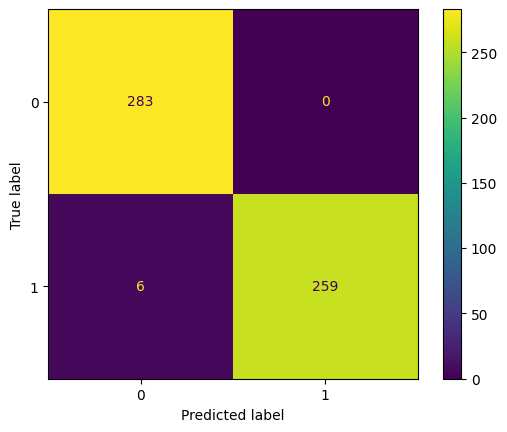

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(model,X_test_tfidf,y_test)

In [ ]:
text=input("Enter text: ")
text=remove_punc(text)
text=remove_emojis(text)
text=text.lower()
text=remove_stopwords(text)
text=tfv.transform([text])
print(model.predict(text))

Enter text: Hi Geeks,  Month End Sale is LIVE, with up to 25% off GeeksforGeeks courses.  The skills you've been planning to learn are now at their lowest prices. But only until 31st October AI Engineer Training Program (Live) ₹ 19,999 -> ₹14,999 System Design Course ₹14,999 -> ₹11,249 Java Backend Course ₹14,999 -> ₹11,249 MERN Full Stack Course ₹7,999 -> ₹5,999 DevOps & Cloud Course ₹14,999 -> ₹11,249 Data Science 360 Course ₹7,999 -> ₹5,999 Placement 360 Course ₹6,999 -> ₹5,249 And so much more DSA & System Design DSA: ₹14,999 -> ₹11,249 SDE Interview Prep: ₹24,999 -> ₹18,749 Sale ends 31st October, 11:59 PM IST. After that, prices go back up. Your next skill has never been this affordable. Don't wait for the next sale.
[0]
